In [1]:
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
from PIL import Image
import os
import shutil
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten, Dropout,GlobalAveragePooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image,image_dataset_from_directory

In [2]:
DATASET_DIR = "Basil"
print(os.listdir(DATASET_DIR))

['Holy_Basil', 'Sweet_basil']


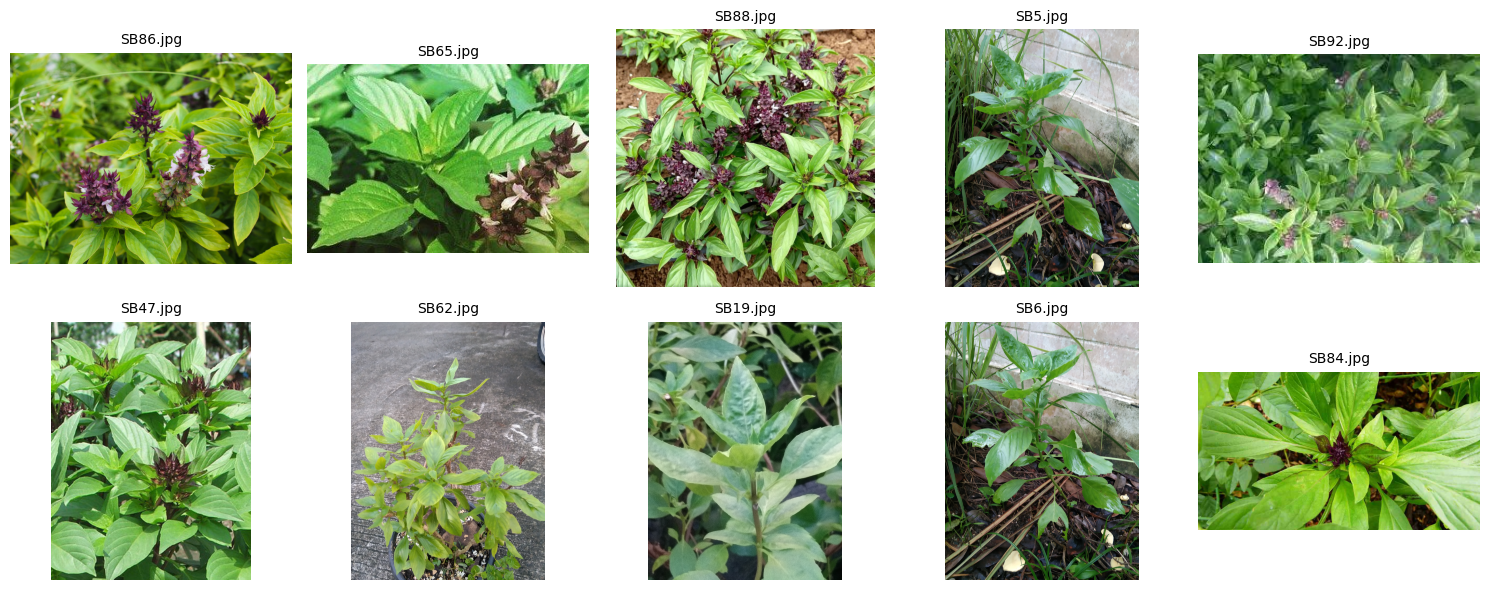

In [3]:
# Define the folder containing cat images
image_folder = os.path.join(DATASET_DIR, 'Sweet_basil')
image_files = os.listdir(image_folder)
# Randomly shuffle the file list to display different images each time
random.shuffle(image_files)


# Function to display 10 images (2 rows x 5 columns)
def display_images(image_folder, image_files):
    # Create a figure with a grid of 2 rows and 5 columns
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    axes = axes.ravel()  # Flatten axes for easy indexing

    for i in range(10):
        if i < len(image_files):  # Check if enough images exist
            # Open the image file
            img = Image.open(os.path.join(image_folder, image_files[i]))
            # Display in grayscale if the image is single-channel (mode 'L')
            if img.mode == 'L':
                axes[i].imshow(img, cmap='gray')
            else:
                axes[i].imshow(img)
            # Set the image file name as the title
            axes[i].set_title(image_files[i], fontsize=10)
            axes[i].axis('off')  # Hide axis ticks and labels
        else:
            # If fewer than 10 images exist, hide the empty subplot
            axes[i].axis('off')

    # Adjust layout for better spacing
    plt.tight_layout()
    plt.show()


# Call the function to display the images
display_images(image_folder, image_files)

In [4]:
# Use the original dataset folder as the source
_base_dir = 'Basil'
# Define the category names (class labels)
categories = ['Holy_basil', 'Sweet_basil']
# Define the split ratios for Train, Validation, and Test sets
split_ratios = {'train': 0.8, 'val': 0.2, 'test': 0}
# Define the output directories where the split data will be stored
output_dirs = {
'train': 'Basil_split/train',
'val': 'Basil_split/val',
'test': 'Basil_split/test'
}


In [5]:
# Function to create output directories and remove them if they already
# exist
def create_output_dirs(output_dirs, categories):
    import shutil
    import os
    for split_dir in output_dirs.values():
        if os.path.exists(split_dir):
            shutil.rmtree(split_dir)
        os.makedirs(split_dir)
        for category in categories:
            os.makedirs(os.path.join(split_dir, category))
# Remove and recreate the output directories
create_output_dirs(output_dirs, categories)

In [6]:
def split_data(category, source_dir, output_dirs, split_ratios):
    import os, random, shutil
    # Pick only valid image files
    valid_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.gif','.webp'}
    files = [
        f for f in os.listdir(source_dir)
        if os.path.isfile(os.path.join(source_dir, f))
        and os.path.splitext(f.lower())[1] in valid_ext
    ]
    random.shuffle(files)
    # Calculate split sizes
    total_files = len(files)
    train_size = int(split_ratios['train'] * total_files)
    val_size = int(split_ratios['val'] * total_files)
    # Split into train / val / test
    train_files = files[:train_size]
    val_files = files[train_size:train_size + val_size]
    test_files = files[train_size + val_size:]
    # Copy files into respective folders
    for file in train_files:
        shutil.copy(os.path.join(source_dir, file),
                    os.path.join(output_dirs['train'], category))
    for file in val_files:
        shutil.copy(os.path.join(source_dir, file),
                    os.path.join(output_dirs['val'], category))
    for file in test_files:
        shutil.copy(os.path.join(source_dir, file),
                    os.path.join(output_dirs['test'], category))
# Run for each category
for category in categories:
    source_dir = os.path.join(_base_dir, category)
    split_data(category, source_dir, output_dirs, split_ratios)
print("Data split completed")

Data split completed


In [7]:
base_dir = 'Basil_split'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

In [8]:
#8. สรCางฟbงกfชันสําหรับโหลดและเตรียมชุดขCอมูลภาพ
# Function to load images and labels
def load_image(image_path, label):
    bytestr = tf.io.read_file(image_path)
    # Decode image (supports multiple formats, takes first frame if GIF)
    img = tf.io.decode_image(bytestr, channels=3, expand_animations=False) # -> RGB [H,W,3]
    img.set_shape([None, None, 3]) # Ensure static channel shape
    img = tf.image.resize(img, [224, 224]) # Resize to target size
    img = tf.cast(img, tf.float32) / 255.0 # Normalize to [0,1]
    return img, label


def prepare_dataset(image_paths, labels, batch_size, shuffle=True):
    # Create dataset from file paths and labels
    ds = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=min(len(image_paths), 10000))  # Shuffle with buffer
    ds = ds.batch(batch_size)
    ds = ds.prefetch(tf.data.AUTOTUNE) # Prefetch for performance
    # Skip broken/unreadable files to avoid training crashes
    ds = ds.apply(tf.data.experimental.ignore_errors())
    return ds


# Load image paths and labels (example: binary classification: 0 = Cat, 1 = Dog)
def load_data(directory):
    image_paths, labels = [], []
    # Use enumerate(categories) to map class -> label index (0..N-1)
    for label, category in enumerate(categories):
        category_dir = os.path.join(directory, category)
        if not os.path.isdir(category_dir):
            continue  # Skip if folder does not exist
        for img_name in os.listdir(category_dir):
            img_path = os.path.join(category_dir, img_name)
            if os.path.isfile(img_path):
                image_paths.append(img_path)
                labels.append(label)
    return image_paths, labels

In [9]:
#9. โหลดและเตรียมชุดขCอมูล
# Load image paths and labels for train, val, and test sets
train_paths, train_labels = load_data(train_dir)
val_paths, val_labels = load_data(val_dir)
test_paths, test_labels = load_data(test_dir)
# Prepare datasets
batch_size = 8
train_dataset = prepare_dataset(train_paths, train_labels,
batch_size, shuffle=True)
val_dataset = prepare_dataset(val_paths, val_labels,
batch_size, shuffle=False)
'''test_dataset = prepare_dataset(test_paths, test_labels,
batch_size, shuffle=False)'''

Instructions for updating:
Use `tf.data.Dataset.ignore_errors` instead.


'test_dataset = prepare_dataset(test_paths, test_labels,\nbatch_size, shuffle=False)'

In [10]:
#10. สรCางโมเดล Convolutional Neural Network ดCวย VGG16
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.applications import InceptionV3
def model_init():
# base_model = InceptionV3(weights=None, include_top=False,input_shape=(299, 299, 3))
  base_model = InceptionV3(weights='imagenet',
                     include_top=False,
                     input_shape=(224, 224, 3))

# Add custom layers
  x = base_model.output
  x = GlobalAveragePooling2D()(x)
  x = Dense(128, activation='relu')(x)
  predictions = Dense(1, activation='sigmoid')(x) # Binaryclassification
  model = Model(inputs=base_model.input,
                outputs=predictions)
  return base_model, model

In [11]:
#11. เตรียมโมเดลสําหรับ Transfer Learning
base_model, model = model_init()
# Freeze base model layers for transfer learning
for layer in base_model.layers:
  layer.trainable = False
# Compile the model
model.compile(optimizer=Adam(learning_rate=0.001),loss='binary_crossentropy', metrics=['accuracy'])

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step


In [12]:
#13. ฝÅกสอนโมเดล
num_epochs = 100
batch_size = 8

print(f"Number of training samples: {len(train_paths)}")
print(f"Batch size: {batch_size}")
# Train the model
history = model.fit(
train_dataset,
validation_data=val_dataset,
epochs=num_epochs
)

Number of training samples: 160
Batch size: 8
Epoch 1/100
     20/Unknown 9s 141ms/step - accuracy: 0.5550 - loss: 1.0949

C:\Users\kasem\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


20/20 ━━━━━━━━━━━━━━━━━━━━ 12s 283ms/step - accuracy: 0.5975 - loss: 0.8451 - val_accuracy: 0.7500 - val_loss: 0.4607
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 157ms/step - accuracy: 0.8931 - loss: 0.3392 - val_accuracy: 0.8250 - val_loss: 0.3469
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - accuracy: 0.9560 - loss: 0.2108 - val_accuracy: 0.8500 - val_loss: 0.2900
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 156ms/step - accuracy: 0.9811 - loss: 0.1465 - val_accuracy: 0.9500 - val_loss: 0.2239
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step - accuracy: 0.9623 - loss: 0.1111 - val_accuracy: 0.9250 - val_loss: 0.2084
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 158ms/step - accuracy: 0.9937 - loss: 0.0839 - val_accuracy: 0.9250 - val_loss: 0.1918
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 158ms/step - accuracy: 0.9874 - loss: 0.0552 - val_accuracy: 0.9000 - val_loss: 0.2153
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - accuracy: 1.0000 - loss: 0.0405 - val_accuracy: 0.900

In [13]:
'''#14. ประเมินโมเดลดCวยชุดทดสอบ
# Load and preprocess the test dataset
test_dataset = prepare_dataset(test_paths, test_labels,
batch_size)
# Evaluate the model using the test dataset
test_loss, test_accuracy = model.evaluate(test_dataset)
# Print the results
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")'''

'#14. ประเมินโมเดลดCวยชุดทดสอบ\n# Load and preprocess the test dataset\ntest_dataset = prepare_dataset(test_paths, test_labels,\nbatch_size)\n# Evaluate the model using the test dataset\ntest_loss, test_accuracy = model.evaluate(test_dataset)\n# Print the results\nprint(f"Test Loss: {test_loss:.4f}")\nprint(f"Test Accuracy: {test_accuracy:.4f}")'

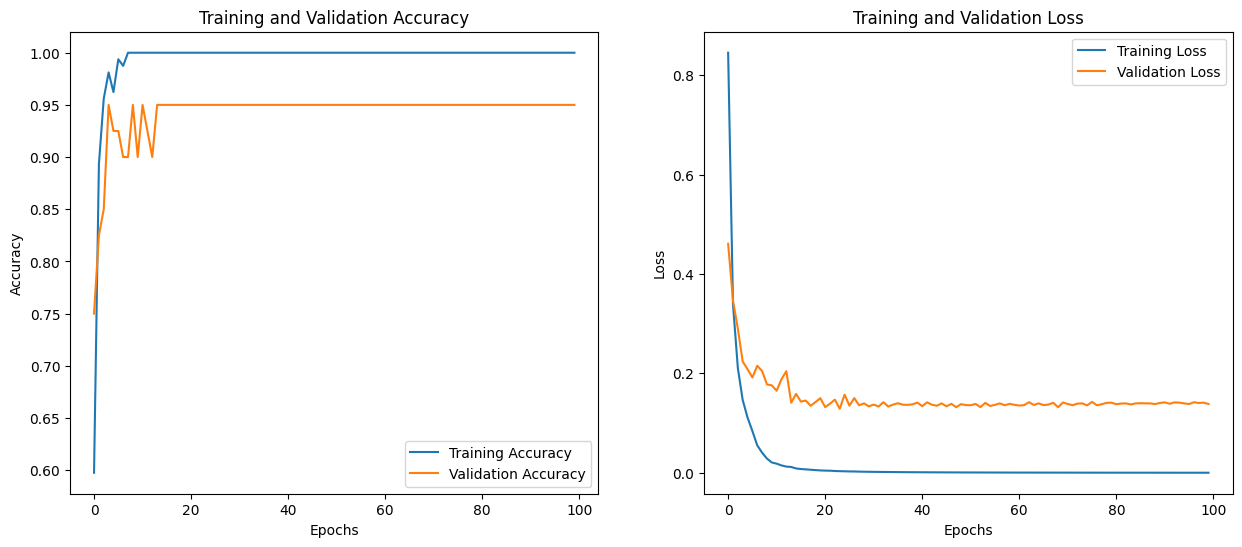

In [14]:
#15. แสดงกราฟ Accuracy และ Loss ระหวhางการฝÅกสอน
# Plotting accuracy and loss curves
def plot_training_results(history):
    acc = history.history['accuracy']
    loss = history.history['loss']
    epochs_range = range(len(acc))

    # Plot Accuracy
    plt.figure(figsize=(15,6))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    if 'val_accuracy' in history.history:
        val_acc = history.history['val_accuracy']
        plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs') # Add x-axis label
    plt.ylabel('Accuracy') # Add y-axis label

    # Plot Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    if 'val_loss' in history.history:
        val_loss = history.history['val_loss']
        plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs') # Add x-axis label
    plt.ylabel('Loss') # Add y-axis label

    plt.show()

# Visualize the results
plot_training_results(history)

In [ ]:
# Save the model with a .keras extension
# Define checkpoint path
CKPT_PATH = 'Basil_split/checkpoint/InceptionV3_model.keras'
# Create the directory if it does not exist
os.makedirs(os.path.dirname(CKPT_PATH), exist_ok=True)
model.save(CKPT_PATH)

In [16]:
#18. โหลดและแปลงรูปภาพใหมhเพื่อใชCทํานาย
# Function to load and preprocess the image (resize and normalize)
def load_and_preprocess_image(image_path, target_size=(224, 224)):
    """
    Load a single image file and return a normalized batch tensor of
    shape (1, H, W, 3)
    """
    bytestr = tf.io.read_file(image_path)
    img = tf.io.decode_image(bytestr, channels=3, expand_animations=False)
    img = tf.image.resize(img, target_size)
    img = tf.cast(img, tf.float32) / 255.0
    img = tf.expand_dims(img, axis=0) # Add batch dimension
    return img

In [17]:
#19. ทํานายผลจากภาพใหมhดCวยโมเดลที่ฝÅกแลCว
# Function to make a prediction using the trained model
def predict_image(model, image_path, threshold=0.5, show=True):
    """
    Predict Cat/Dog from an image_path using binary sigmoid output.
    Returns: (pred_label_str, prob_float)
    """
    x = load_and_preprocess_image(image_path)
    if show:
        disp = tf.keras.utils.load_img(image_path)
        plt.imshow(disp); plt.axis('off');
        plt.title(os.path.basename(image_path))
        plt.show()
    pred = model.predict(x, verbose=0)
    # pred.shape -> (1,1)
    prob = float(pred[0][0])
    idx = 1 if prob >= threshold else 0
    label = categories[idx]
    print(f"Prediction: {label} (Confidence: {prob:.4f})")
    return label, prob

In [18]:
'''#20. ทํานายผลแบบสุhมจากชุดทดสอบ
test_dir = os.path.join('Basil_split', 'test')
def predict_random_samples(test_dir, n_each=1):
 valid_ext = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
 for cls in categories:
  cls_dir = os.path.join(test_dir, cls)
  if not os.path.isdir(cls_dir):
   print(f"[WARN] Missing directory: {cls_dir}")
   continue
  # Collect all valid image files in this class folder
  files = [f for f in os.listdir(cls_dir)
   if os.path.splitext(f.lower())[1] in valid_ext
   and os.path.isfile(os.path.join(cls_dir, f))]
  if not files:
   print(f"[WARN] No valid images in: {cls_dir}")
   continue
  # Shuffle and pick 'n_each' random samples
  random.shuffle(files)
  for f in files[:n_each]:
   path = os.path.join(cls_dir, f)
   print(f"[Sample] {cls} -> {f}")
   # Call prediction function with visualization
   predict_image(model, path, threshold=0.5, show=True)
# Demo: predict 5 random samples from each class
predict_random_samples(test_dir, n_each=5)'''

'#20. ทํานายผลแบบสุhมจากชุดทดสอบ\ntest_dir = os.path.join(\'Basil_split\', \'test\')\ndef predict_random_samples(test_dir, n_each=1):\n valid_ext = {\'.jpg\', \'.jpeg\', \'.png\', \'.bmp\', \'.gif\'}\n for cls in categories:\n  cls_dir = os.path.join(test_dir, cls)\n  if not os.path.isdir(cls_dir):\n   print(f"[WARN] Missing directory: {cls_dir}")\n   continue\n  # Collect all valid image files in this class folder\n  files = [f for f in os.listdir(cls_dir)\n   if os.path.splitext(f.lower())[1] in valid_ext\n   and os.path.isfile(os.path.join(cls_dir, f))]\n  if not files:\n   print(f"[WARN] No valid images in: {cls_dir}")\n   continue\n  # Shuffle and pick \'n_each\' random samples\n  random.shuffle(files)\n  for f in files[:n_each]:\n   path = os.path.join(cls_dir, f)\n   print(f"[Sample] {cls} -> {f}")\n   # Call prediction function with visualization\n   predict_image(model, path, threshold=0.5, show=True)\n# Demo: predict 5 random samples from each class\npredict_random_samples(te